# Practical Assignment: Clustering on a Real-World Dataset

| | |
|---|---|
| **Name** | Yash Galande |
| **PRN / Roll No.** | 202401040179 |
| **Division / Batch** | A2 – 41 |
| **Subject** | AIML |

**Objective:** Apply clustering algorithms to a real-world dataset to find meaningful groups, and evaluate cluster quality using the Silhouette score, Davies-Bouldin index, Calinski-Harabasz index and visual inspection.

## 🔗 Google Colab & GitHub Links

- **Google Colab notebook:** [Open in Colab](PASTE_YOUR_COLAB_LINK_HERE)
- **GitHub repository:** [PASTE_YOUR_GITHUB_LINK_HERE](PASTE_YOUR_GITHUB_LINK_HERE)

> Upload this `.ipynb` to Colab → *Share* → "Anyone with the link" → paste the link. Push the notebook to a GitHub repo and paste the repo URL.

## 1. Import Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.mixture import GaussianMixture
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import (silhouette_score, silhouette_samples, davies_bouldin_score,
                             calinski_harabasz_score, adjusted_rand_score)
from scipy.cluster.hierarchy import dendrogram, linkage

sns.set_style('whitegrid')
RANDOM_STATE = 42

## 2. Load and Explore the Dataset
The **Wine dataset** is real-world data: a chemical analysis of 178 wines grown in the same region of Italy from 3 different cultivars, described by 13 chemical features (alcohol, flavanoids, colour intensity, proline, etc.). It is built into scikit-learn, so no upload is needed.

The cultivar labels are **not used for clustering** (unsupervised). They are only used at the end as an external sanity check.

In [2]:
wine = load_wine()
X = pd.DataFrame(wine.data, columns=wine.feature_names)
y_true = wine.target

print('Shape:', X.shape)
print('Missing values:', X.isnull().sum().sum())
X.describe().T.round(2)

Shape: (178, 13)
Missing values: 0


,count,mean,std,min,25%,50%,75%,max
alcohol,178.0,13.00,0.81,11.03,12.36,13.05,13.68,14.83
malic_acid,178.0,2.34,1.12,0.74,1.60,1.87,3.08,5.80
ash,178.0,2.37,0.27,1.36,2.21,2.36,2.56,3.23
alcalinity_of_ash,178.0,19.49,3.34,10.60,17.20,19.50,21.50,30.00
magnesium,178.0,99.74,14.28,70.00,88.00,98.00,107.00,162.00
total_phenols,178.0,2.30,0.63,0.98,1.74,2.36,2.80,3.88
flavanoids,178.0,2.03,1.00,0.34,1.20,2.13,2.88,5.08
nonflavanoid_phenols,178.0,0.36,0.12,0.13,0.27,0.34,0.44,0.66
proanthocyanins,178.0,1.59,0.57,0.41,1.25,1.56,1.95,3.58
color_intensity,178.0,5.06,2.32,1.28,3.22,4.69,6.20,13.00


### 2.1 Feature correlation

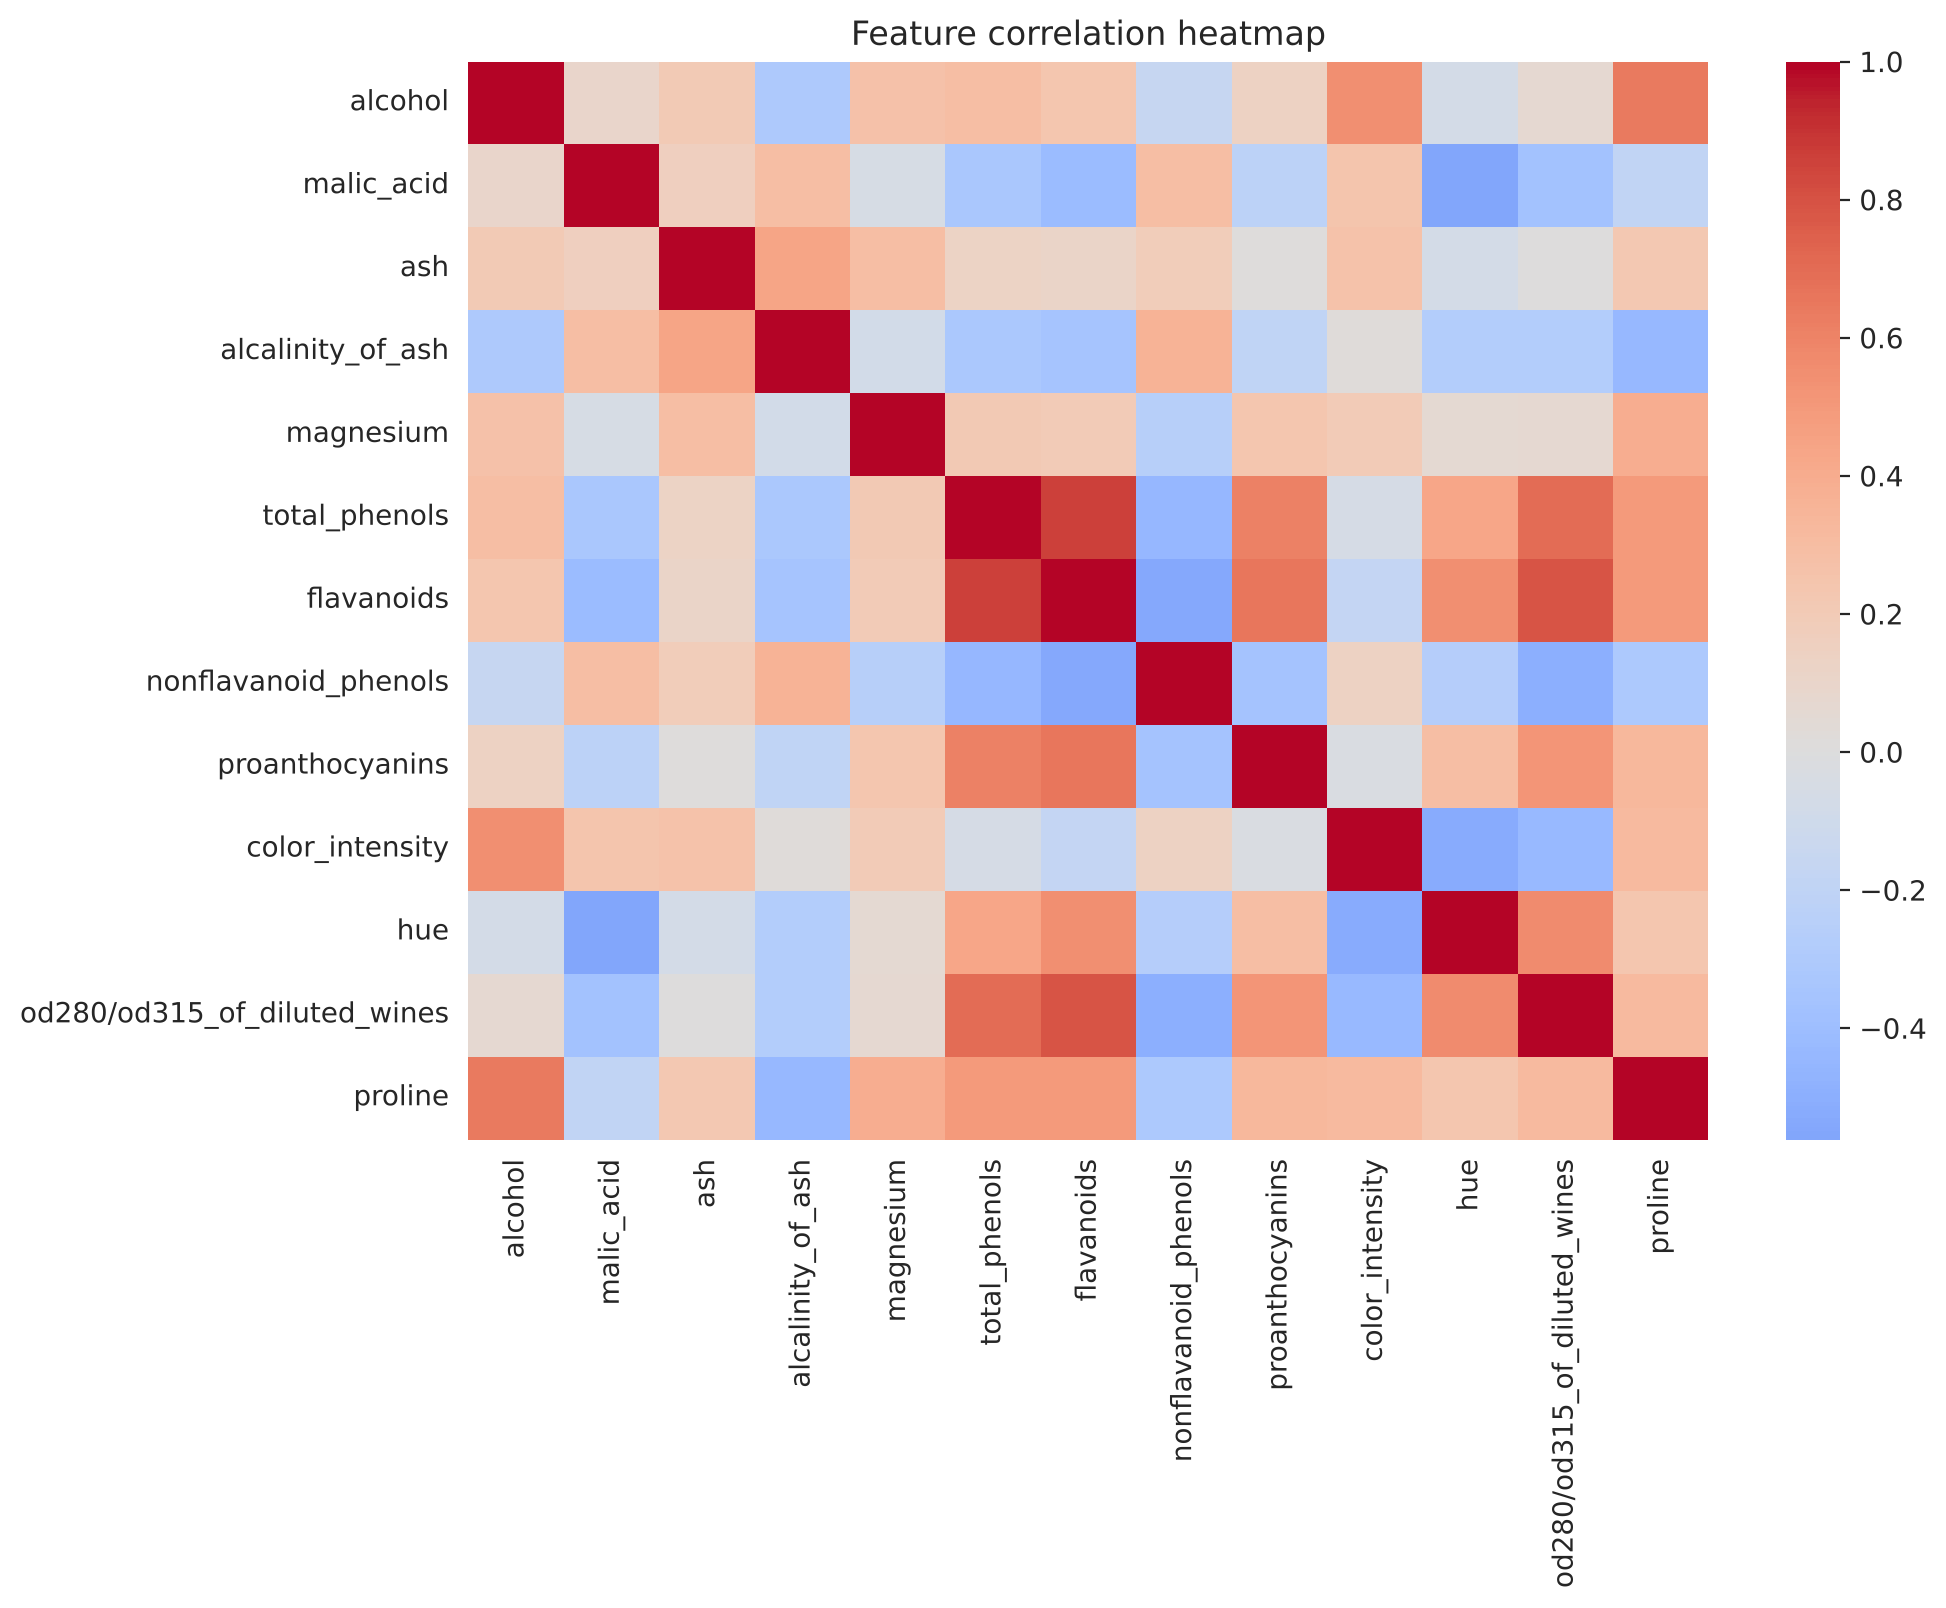

In [3]:
plt.figure(figsize=(10,7))
sns.heatmap(X.corr(), cmap='coolwarm', center=0, annot=False)
plt.title('Feature correlation heatmap'); plt.show()

## 3. Preprocessing
Features are on very different scales (proline is in the hundreds, hue is below 2). Clustering algorithms use distances, so we **standardise** all features (mean 0, std 1).

In [4]:
X_scaled = StandardScaler().fit_transform(X)

# 2-D PCA projection used only for visualising the clusters
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_scaled)
print('Variance explained by 2 PCs: %.1f%%' % (pca.explained_variance_ratio_.sum()*100))

Variance explained by 2 PCs: 55.4%


## 4. K-Means Clustering
### 4.1 Choosing k: Elbow method + Silhouette + Davies-Bouldin

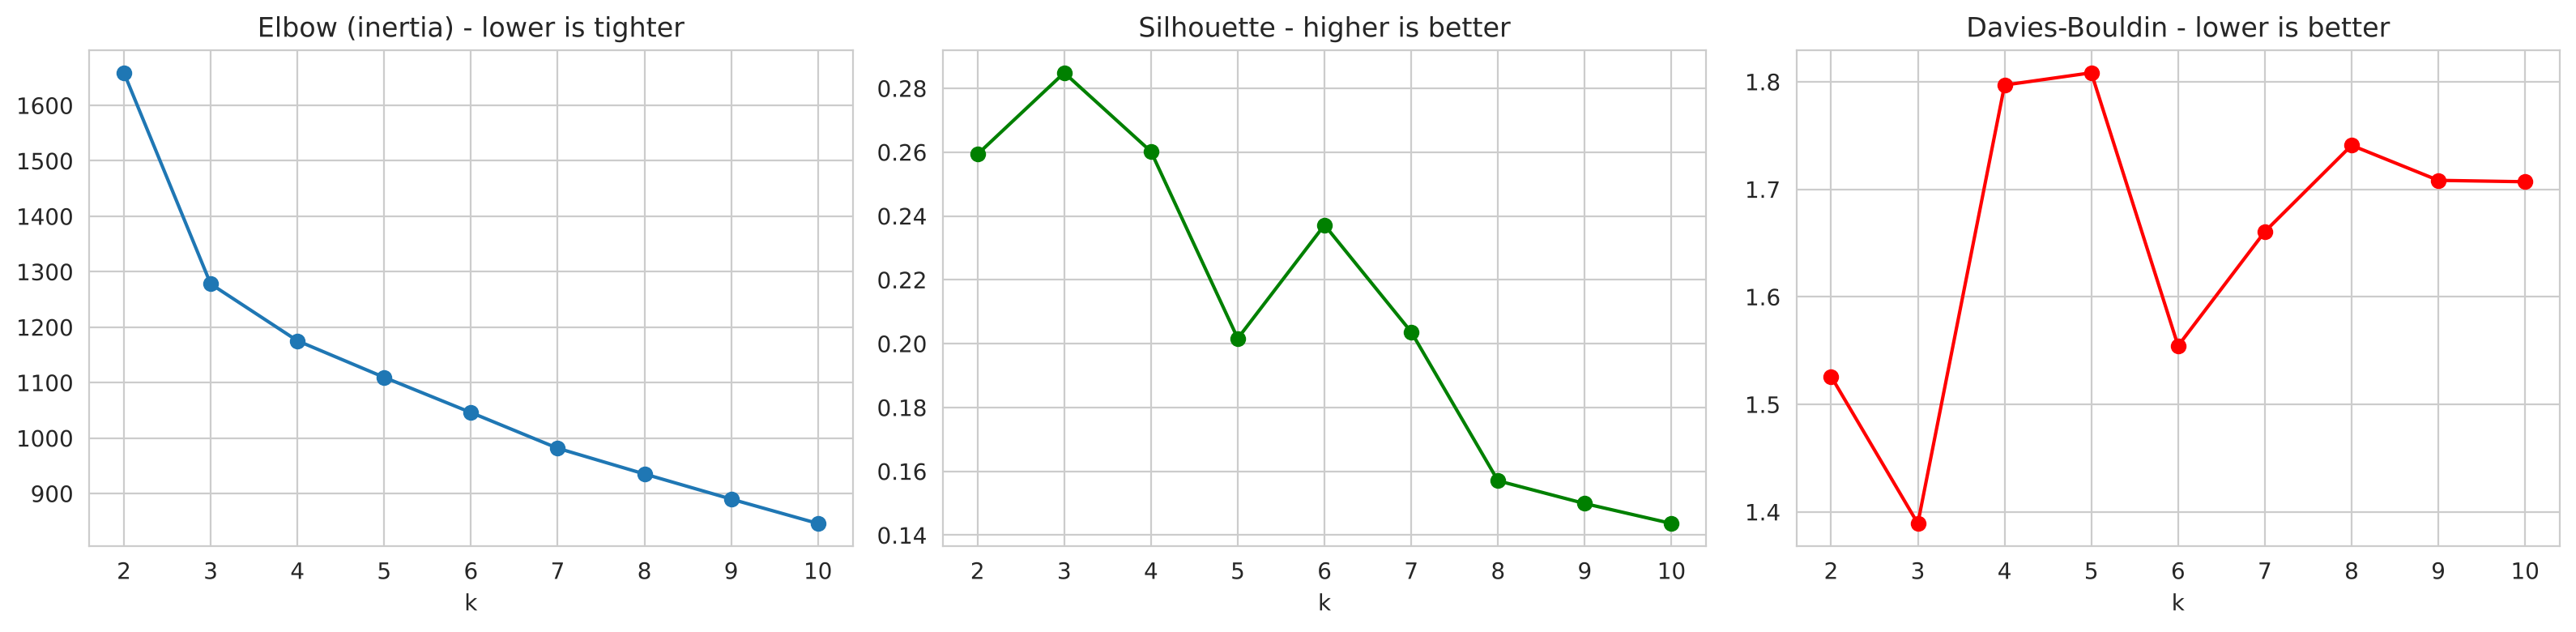

,Silhouette,Davies-Bouldin,Calinski-Harabasz
k,,,
2,0.2593,1.5260,69.5
3,0.2849,1.3892,70.9
4,0.2602,1.7969,56.2
5,0.2016,1.8083,47.0
6,0.2372,1.5544,41.7
7,0.2036,1.6606,38.7
8,0.1570,1.7409,35.8
9,0.1499,1.7083,33.8
10,0.1436,1.7070,32.4


In [5]:
ks = range(2, 11)
inertia, sil, dbi, chi = [], [], [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X_scaled)
    inertia.append(km.inertia_)
    sil.append(silhouette_score(X_scaled, km.labels_))
    dbi.append(davies_bouldin_score(X_scaled, km.labels_))
    chi.append(calinski_harabasz_score(X_scaled, km.labels_))

fig, ax = plt.subplots(1, 3, figsize=(16,4))
ax[0].plot(ks, inertia, 'o-'); ax[0].set_title('Elbow (inertia) - lower is tighter')
ax[1].plot(ks, sil, 'o-', color='green'); ax[1].set_title('Silhouette - higher is better')
ax[2].plot(ks, dbi, 'o-', color='red'); ax[2].set_title('Davies-Bouldin - lower is better')
for a in ax: a.set_xlabel('k')
plt.tight_layout(); plt.show()

pd.DataFrame({'k':list(ks),'Silhouette':np.round(sil,4),'Davies-Bouldin':np.round(dbi,4),
              'Calinski-Harabasz':np.round(chi,1)}).set_index('k')

In [6]:
best_k = list(ks)[int(np.argmax(sil))]
print('k with the best silhouette score:', best_k)

k with the best silhouette score: 3


### 4.2 Final K-Means model (k = 3) and silhouette plot

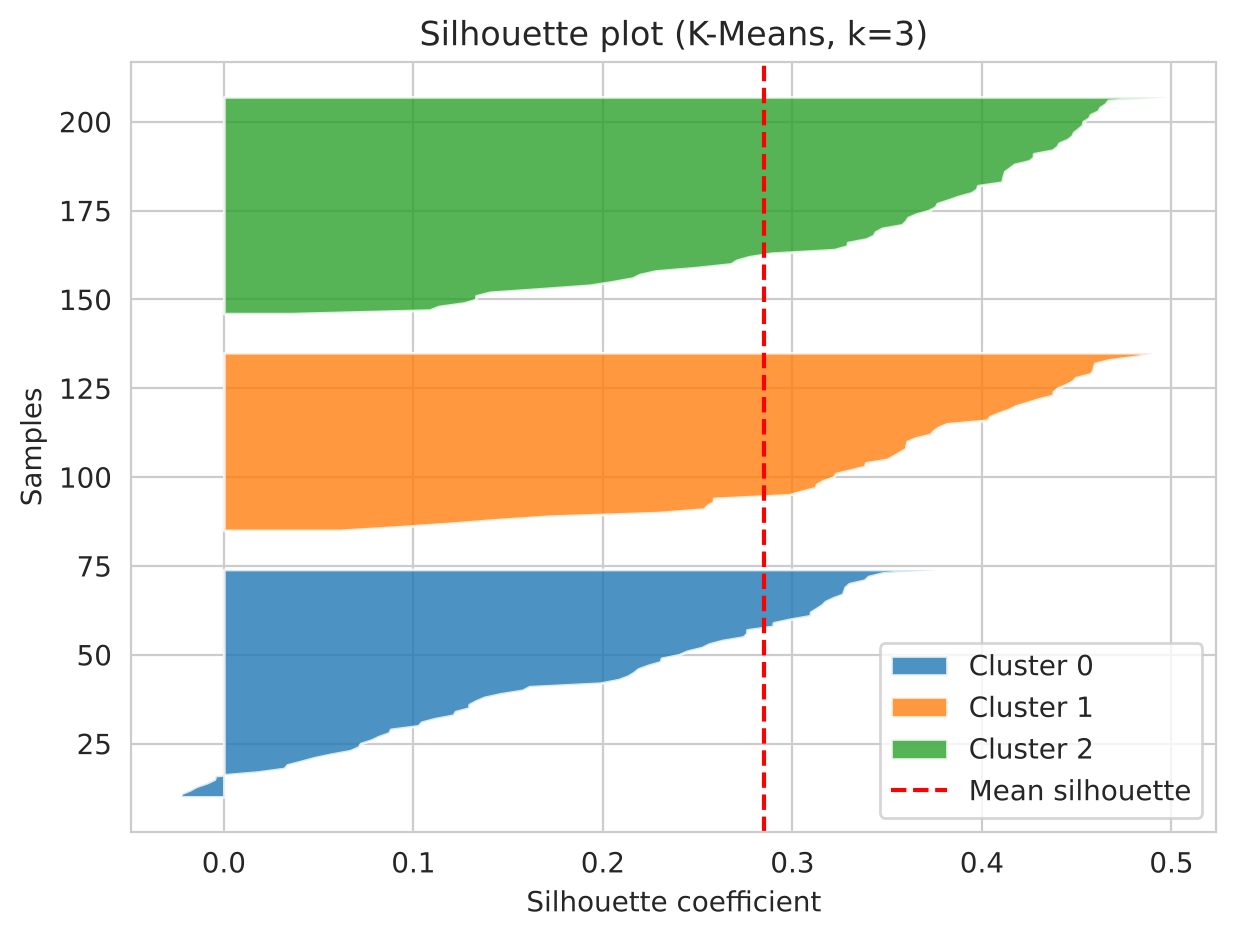

In [7]:
K = 3
kmeans = KMeans(n_clusters=K, n_init=10, random_state=RANDOM_STATE).fit(X_scaled)
km_labels = kmeans.labels_

sample_sil = silhouette_samples(X_scaled, km_labels)
fig, ax = plt.subplots(figsize=(7,5))
y_lower = 10
for i in range(K):
    vals = np.sort(sample_sil[km_labels == i])
    y_upper = y_lower + len(vals)
    ax.fill_betweenx(np.arange(y_lower, y_upper), 0, vals, alpha=0.8, label=f'Cluster {i}')
    y_lower = y_upper + 10
ax.axvline(silhouette_score(X_scaled, km_labels), color='red', linestyle='--', label='Mean silhouette')
ax.set_xlabel('Silhouette coefficient'); ax.set_ylabel('Samples'); ax.set_title('Silhouette plot (K-Means, k=3)')
ax.legend(); plt.show()

## 5. Hierarchical (Agglomerative) Clustering

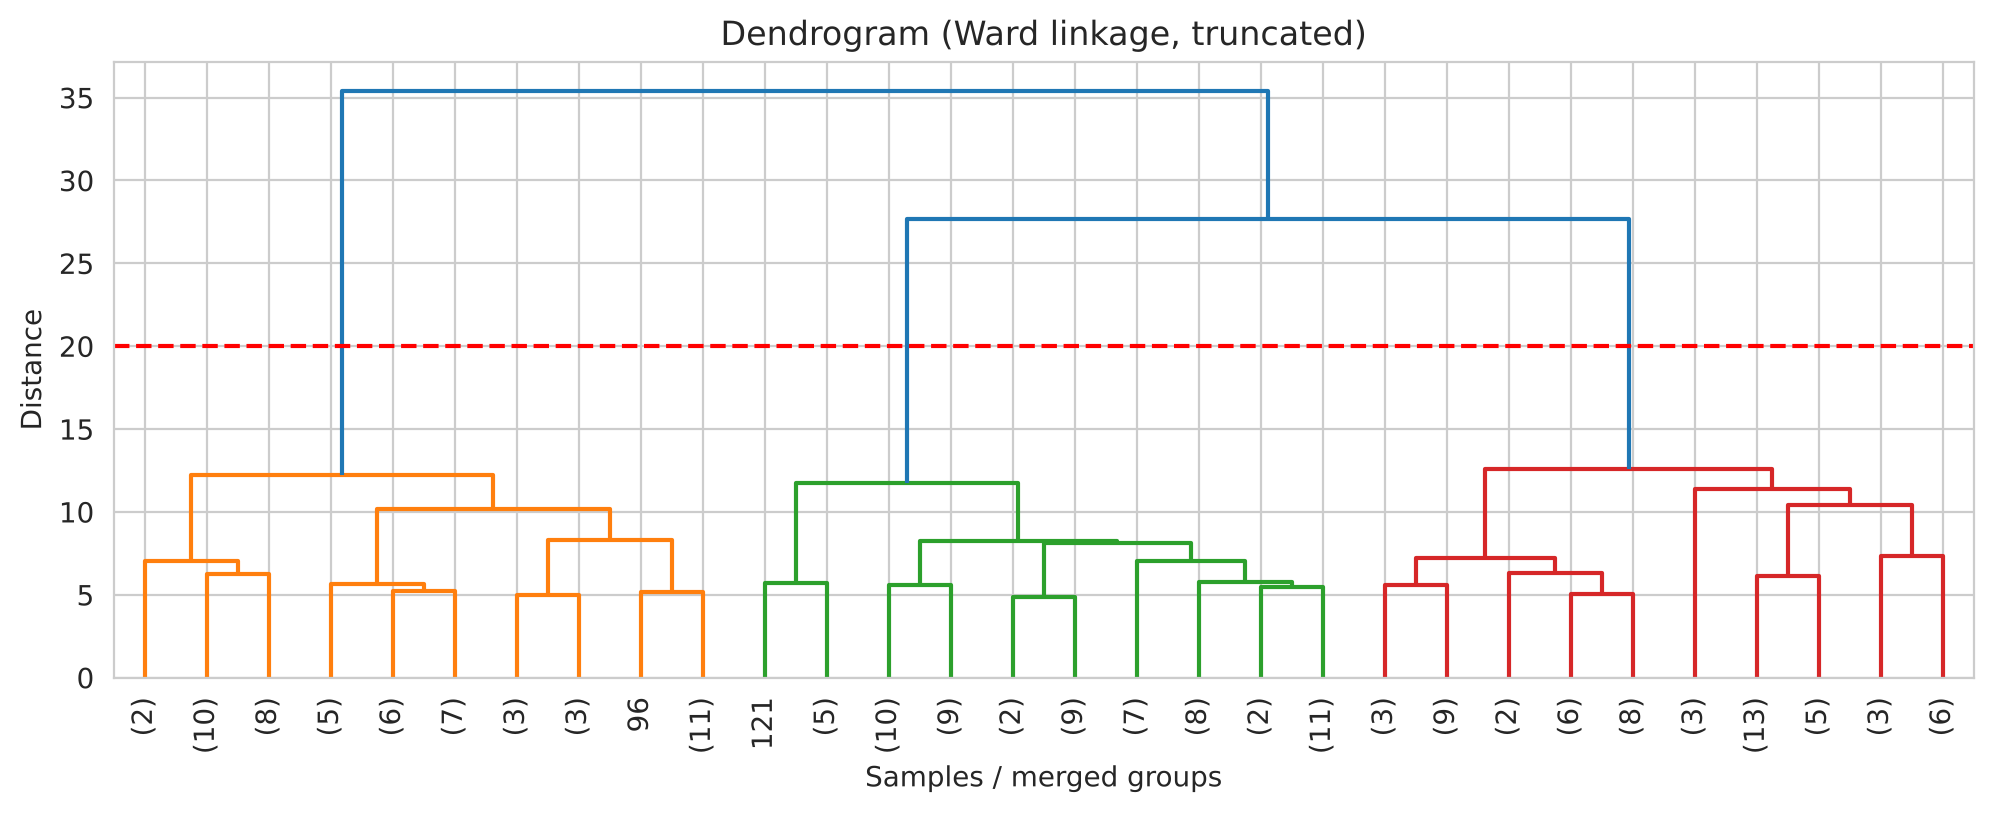

In [8]:
Z = linkage(X_scaled, method='ward')
plt.figure(figsize=(12,4))
dendrogram(Z, truncate_mode='lastp', p=30, leaf_rotation=90, no_labels=False)
plt.axhline(y=20, color='r', linestyle='--'); plt.title('Dendrogram (Ward linkage, truncated)')
plt.xlabel('Samples / merged groups'); plt.ylabel('Distance'); plt.show()

agg = AgglomerativeClustering(n_clusters=3, linkage='ward').fit(X_scaled)
agg_labels = agg.labels_

## 6. DBSCAN (Density-based)
`eps` is chosen using the k-distance plot (look for the "knee"). `min_samples` is set to 2 x dimensions would be too strict for 178 points, so we use a small value and tune.

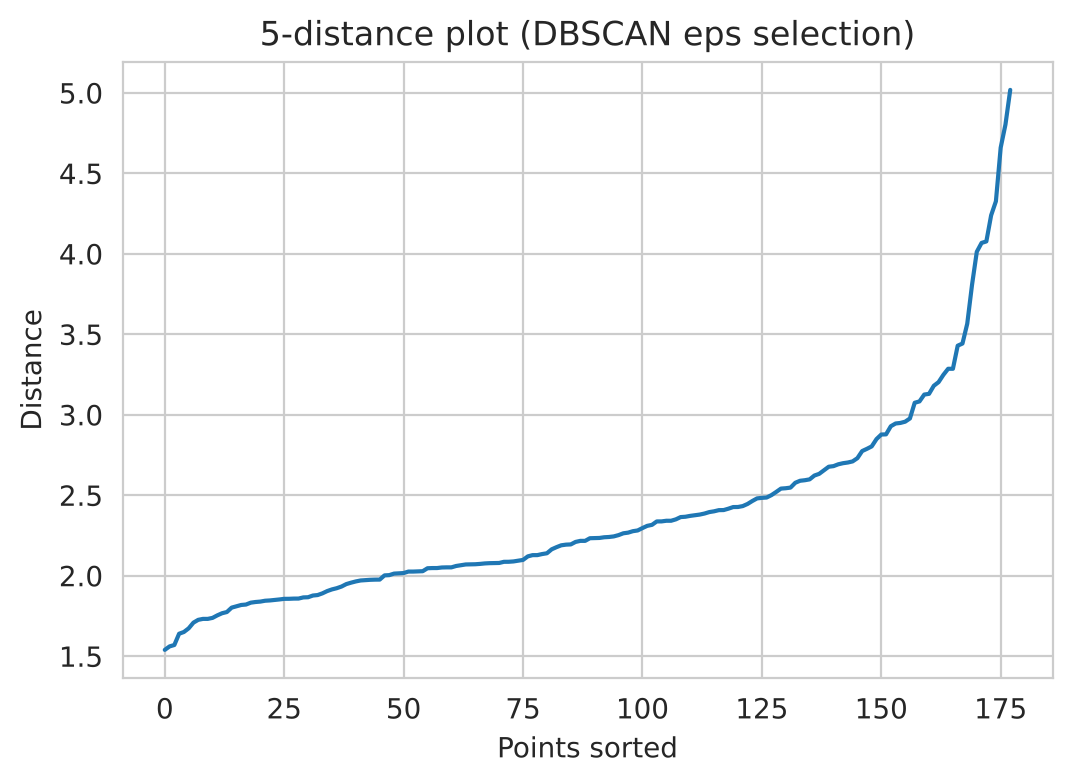

In [9]:
k = 5
nn = NearestNeighbors(n_neighbors=k).fit(X_scaled)
dist, _ = nn.kneighbors(X_scaled)
plt.figure(figsize=(6,4)); plt.plot(np.sort(dist[:, -1]))
plt.title(f'{k}-distance plot (DBSCAN eps selection)'); plt.ylabel('Distance'); plt.xlabel('Points sorted'); plt.show()

In [10]:
# grid search over eps / min_samples, scored by silhouette (noise excluded).
# Settings that label more than 30% of the data as noise are rejected, otherwise the score is misleading.
rows = []
for eps in np.arange(1.5, 3.6, 0.25):
    for ms in [3, 5, 7]:
        lab = DBSCAN(eps=eps, min_samples=ms).fit_predict(X_scaled)
        mask = lab != -1
        ncl = len(set(lab[mask]))
        if ncl >= 2 and (~mask).sum() <= 0.30 * len(X_scaled):
            rows.append({'eps':round(eps,2),'min_samples':ms,'clusters':ncl,'noise':int((~mask).sum()),
                         'silhouette':silhouette_score(X_scaled[mask], lab[mask])})
grid = pd.DataFrame(rows).sort_values('silhouette', ascending=False)
display(grid.head(8).round(4))

,eps,min_samples,clusters,noise,silhouette
1,2.25,5,2,46,0.3371
0,2.25,3,2,37,0.3313
2,3.00,3,2,7,0.2392
3,3.25,3,2,5,0.2369
4,3.50,3,2,3,0.2308


In [11]:
best = grid.iloc[0]
db = DBSCAN(eps=best['eps'], min_samples=int(best['min_samples'])).fit(X_scaled)
db_labels = db.labels_
print('DBSCAN -> clusters:', len(set(db_labels) - {-1}), '| noise points:', int((db_labels == -1).sum()))

DBSCAN -> clusters: 2 | noise points: 46


## 7. Gaussian Mixture Model (soft clustering)

In [12]:
gmm = GaussianMixture(n_components=3, covariance_type='full', n_init=5, random_state=RANDOM_STATE).fit(X_scaled)
gmm_labels = gmm.predict(X_scaled)
print('GMM BIC:', round(gmm.bic(X_scaled), 1))

GMM BIC: 5806.3


## 8. Evaluation and Comparison of Clustering Results
- **Silhouette** (-1 to 1, higher is better) - cohesion vs separation
- **Davies-Bouldin** (>= 0, lower is better) - average similarity between clusters
- **Calinski-Harabasz** (higher is better) - between/within cluster variance ratio
- **Adjusted Rand Index** (external, 1 = perfect match) - uses the true wine cultivars, only as a sanity check. For DBSCAN, noise points are excluded from internal metrics.

In [13]:
def evaluate(name, labels):
    mask = labels != -1
    n_cl = len(set(labels[mask]))
    r = {'Algorithm': name, 'Clusters': n_cl, 'Noise pts': int((~mask).sum())}
    if n_cl >= 2:
        r['Silhouette'] = silhouette_score(X_scaled[mask], labels[mask])
        r['Davies-Bouldin'] = davies_bouldin_score(X_scaled[mask], labels[mask])
        r['Calinski-Harabasz'] = calinski_harabasz_score(X_scaled[mask], labels[mask])
    r['ARI (vs true)'] = adjusted_rand_score(y_true, labels)
    return r

all_labels = {'K-Means': km_labels, 'Hierarchical (Ward)': agg_labels,
              'DBSCAN': db_labels, 'Gaussian Mixture': gmm_labels}
results = pd.DataFrame([evaluate(n, l) for n, l in all_labels.items()]).set_index('Algorithm').round(4)
results

,Clusters,Noise pts,Silhouette,Davies-Bouldin,Calinski-Harabasz,ARI (vs true)
Algorithm,,,,,,
K-Means,3,0,0.2849,1.3892,70.9400,0.8975
Hierarchical (Ward),3,0,0.2774,1.4186,67.6475,0.7899
DBSCAN,2,46,0.3371,1.1712,71.0774,0.3962
Gaussian Mixture,3,0,0.2844,1.3938,70.6878,0.8804


### 8.1 Visual inspection (PCA projection)

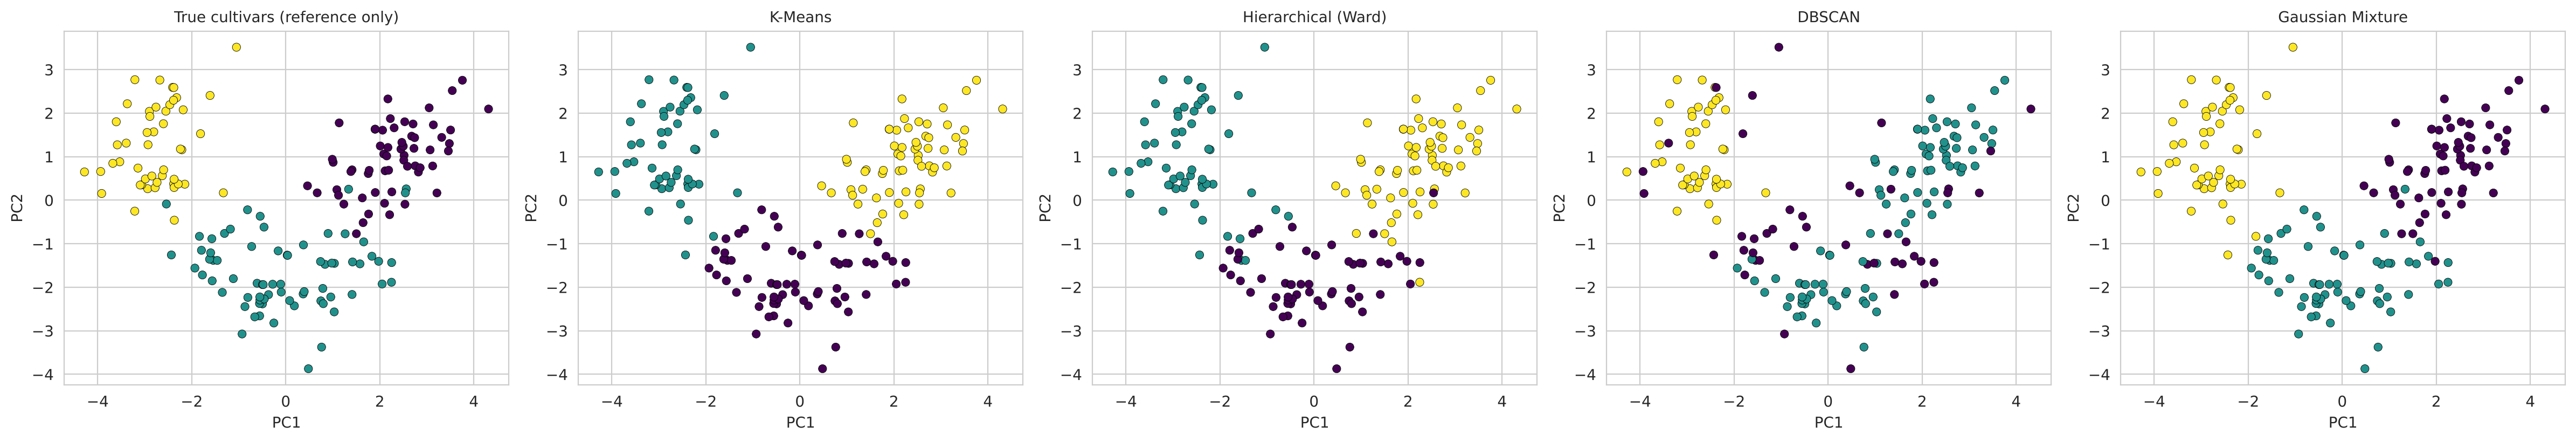

In [14]:
fig, axes = plt.subplots(1, 5, figsize=(24, 4.2))
panels = [('True cultivars (reference only)', y_true)] + list(all_labels.items())
for ax, (title, lab) in zip(axes, panels):
    sc = ax.scatter(X_pca[:,0], X_pca[:,1], c=lab, cmap='viridis', s=30, edgecolor='k', linewidth=0.3)
    ax.set_title(title, fontsize=10); ax.set_xlabel('PC1'); ax.set_ylabel('PC2')
plt.tight_layout(); plt.show()

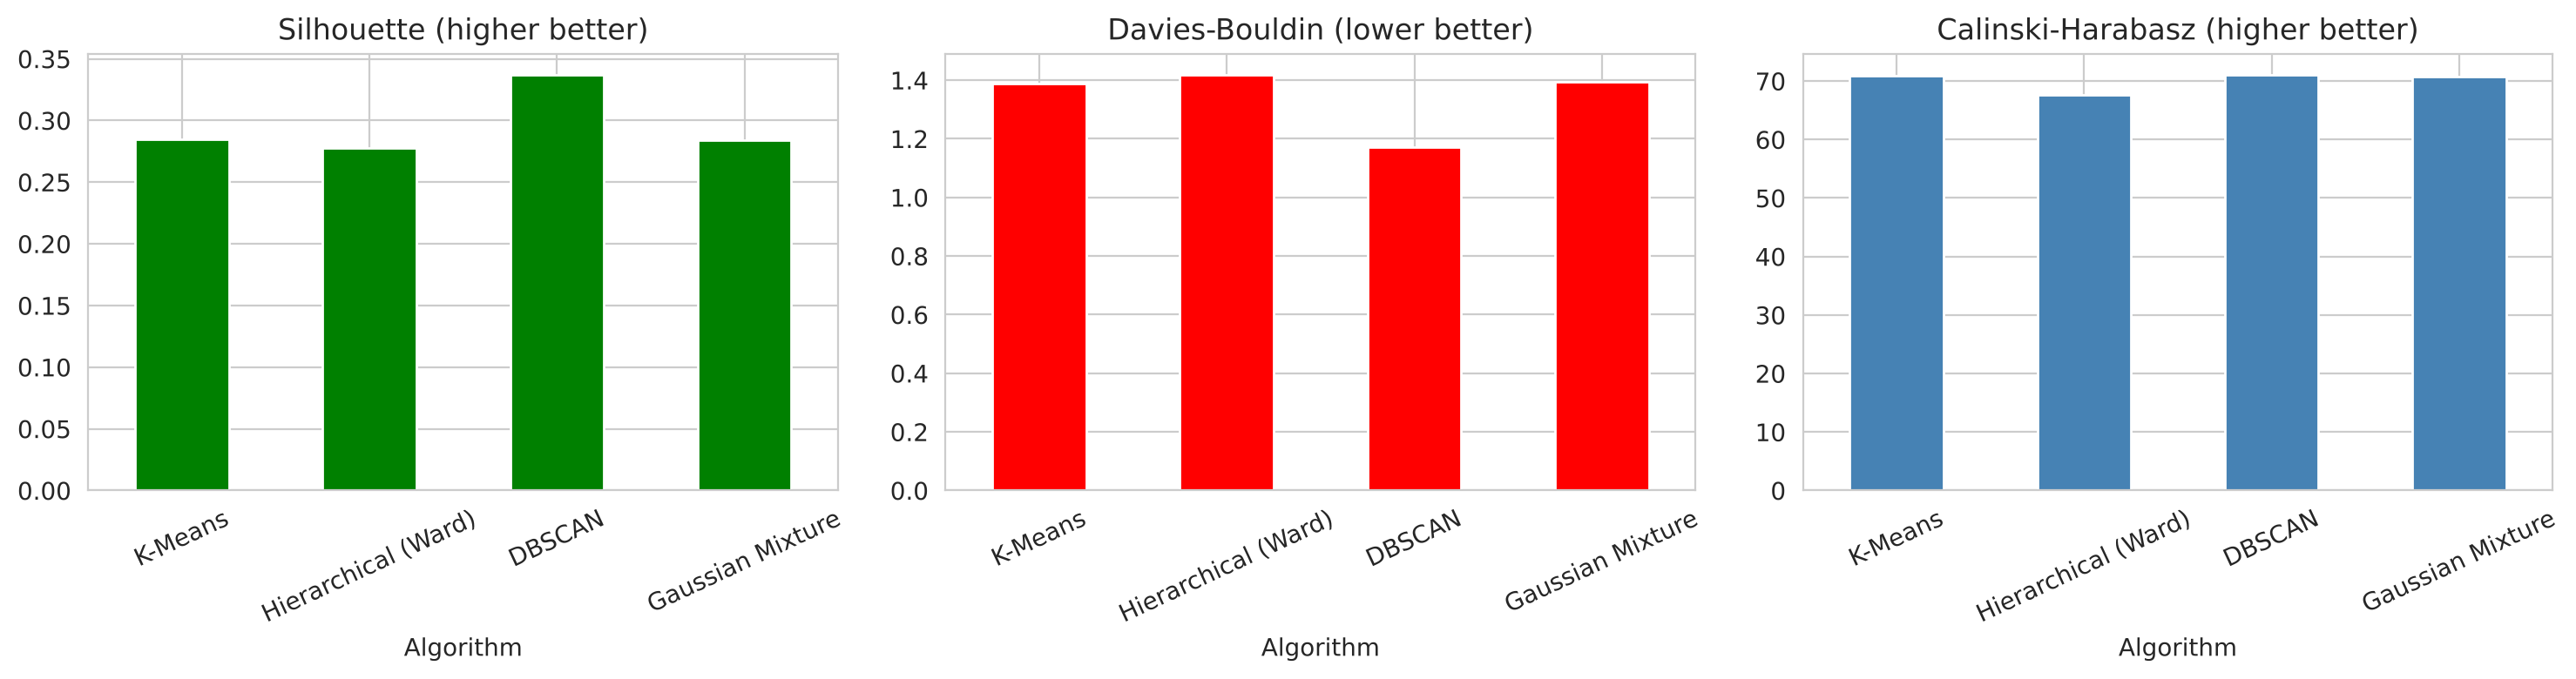

In [15]:
fig, ax = plt.subplots(1, 3, figsize=(15,4))
res = results.dropna(subset=['Silhouette'])
res['Silhouette'].plot(kind='bar', ax=ax[0], color='green'); ax[0].set_title('Silhouette (higher better)')
res['Davies-Bouldin'].plot(kind='bar', ax=ax[1], color='red'); ax[1].set_title('Davies-Bouldin (lower better)')
res['Calinski-Harabasz'].plot(kind='bar', ax=ax[2], color='steelblue'); ax[2].set_title('Calinski-Harabasz (higher better)')
for a in ax: a.tick_params(axis='x', rotation=25)
plt.tight_layout(); plt.show()

### 8.2 Cluster profiling (what does each K-Means group mean?)

Cluster,0,1,2
alcohol,12.25,13.13,13.68
malic_acid,1.90,3.31,2.00
ash,2.23,2.42,2.47
alcalinity_of_ash,20.06,21.24,17.46
magnesium,92.74,98.67,107.97
total_phenols,2.25,1.68,2.85
flavanoids,2.05,0.82,3.00
nonflavanoid_phenols,0.36,0.45,0.29
proanthocyanins,1.62,1.15,1.92
color_intensity,2.97,7.23,5.45


Cluster sizes: {0: np.int64(65), 1: np.int64(51), 2: np.int64(62)}


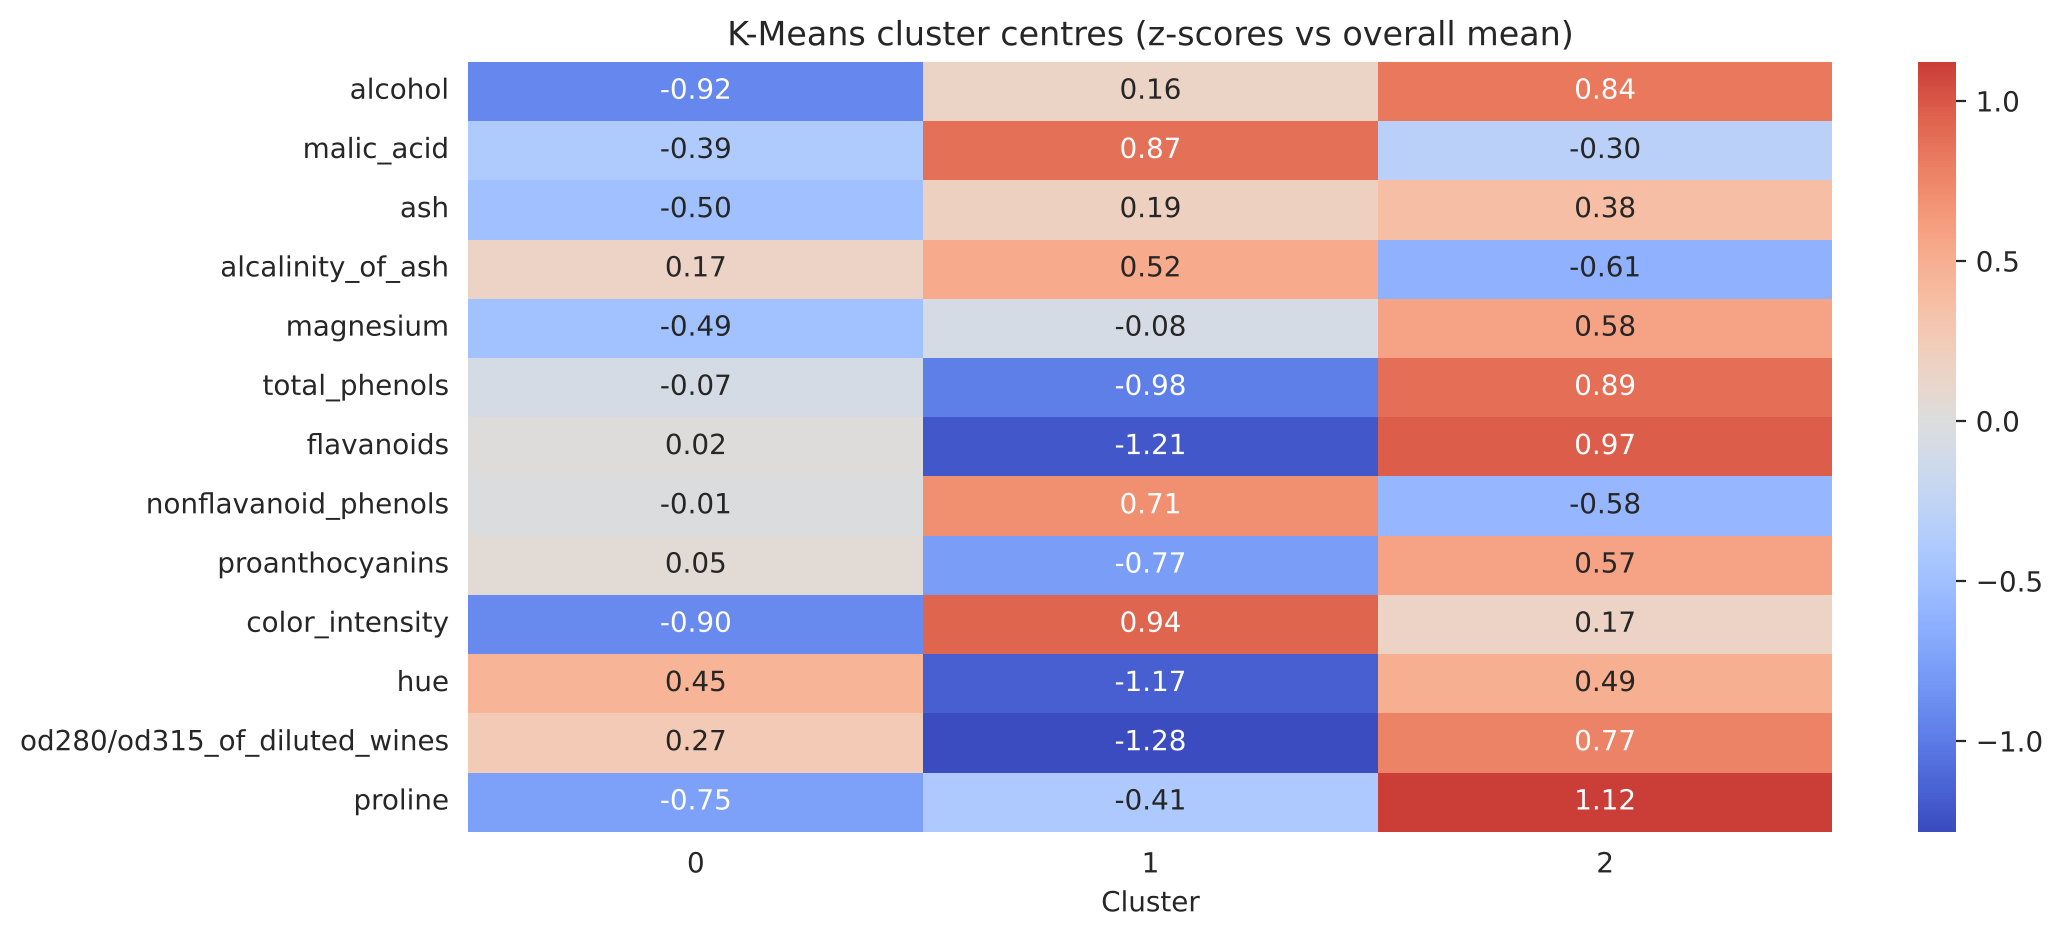

In [16]:
profile = X.copy(); profile['Cluster'] = km_labels
prof = profile.groupby('Cluster').mean().round(2)
display(prof.T)
print('Cluster sizes:', dict(pd.Series(km_labels).value_counts().sort_index()))

plt.figure(figsize=(11,5))
sns.heatmap(((prof - X.mean()) / X.std()).T, annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('K-Means cluster centres (z-scores vs overall mean)'); plt.show()

In [17]:
# How do clusters line up with the real cultivars?
print(pd.crosstab(pd.Series(y_true, name='True cultivar'), pd.Series(km_labels, name='K-Means cluster')))

K-Means cluster   0   1   2
True cultivar              
0                 0   0  59
1                65   3   3
2                 0  48   0


## 9. Summary of Findings

**Choosing the number of clusters:** The silhouette score peaked at k = 3 (0.285) and the Davies-Bouldin index was lowest at k = 3 (1.39). The elbow plot also bends around 3, so all three criteria agree on **3 clusters**.

**Algorithm comparison** (standardised data, from my run with random_state=42)

| Algorithm | Clusters | Silhouette | Davies-Bouldin | ARI vs true cultivars |
|---|---|---|---|---|
| K-Means | 3 | 0.285 | 1.39 | **0.90** |
| Gaussian Mixture | 3 | 0.284 | 1.39 | 0.88 |
| Hierarchical (Ward) | 3 | 0.277 | 1.42 | 0.79 |
| DBSCAN | 2 (+46 noise points) | 0.337 | 1.17 | 0.40 |

- **K-Means and Gaussian Mixture** performed best and nearly identically. Both recover the 3 real wine cultivars well (ARI about 0.88-0.90).
- **Hierarchical clustering** is slightly worse here, but its dendrogram also suggests 3 groups, which supports the choice of k.
- **DBSCAN** has the highest silhouette score, but this is misleading. It marks 46 of 178 wines (26%) as noise and merges the real groups into only 2 clusters, and the score is computed without the noise points. Its low ARI (0.40) shows it matches the real structure poorly. Internal metrics alone can be deceptive, so they should be combined with visual inspection and domain knowledge.
- Overall silhouette values (about 0.28) are modest, meaning the clusters overlap somewhat. This is visible in the PCA plots, where the groups are separated but touch at the edges.

**Cluster profiles (K-Means):**
- **Cluster 2 (62 wines):** high alcohol, flavanoids, total phenols and proline. These are strong, phenol-rich wines.
- **Cluster 1 (51 wines):** high malic acid and colour intensity, with low flavanoids and hue. These are dark, acidic wines with few phenols.
- **Cluster 0 (65 wines):** low alcohol and low colour intensity. These are lighter wines.

The cross-tabulation shows K-Means separates the three cultivars almost perfectly (only 6 of 178 wines are placed in a different group from their true cultivar).

**When to use each algorithm**

| Algorithm | Best when | Limitations |
|---|---|---|
| **K-Means** | Roughly spherical, similar-sized clusters; large data; need speed | Must choose k; sensitive to outliers and scaling |
| **Hierarchical** | Small/medium data; want a dendrogram and no fixed k up front | Slow on large data; early merges cannot be undone |
| **DBSCAN** | Irregular cluster shapes, noise/outliers present, clusters of similar density | Hard to tune `eps`; struggles with varying densities and high dimensions |
| **Gaussian Mixture** | Overlapping or elliptical clusters; need soft (probabilistic) assignments | Assumes Gaussian shapes; can overfit; slower |

**Limitations and further improvements**
- Try other real-world data (e.g. customer segmentation, mall customers) and larger datasets
- Apply feature selection or dimensionality reduction (PCA, UMAP) before clustering, since 13 features include some redundant ones
- Try other methods (HDBSCAN, spectral clustering, K-Medoids) and other linkages
- Test cluster stability using bootstrapping or different random seeds
- Use t-SNE/UMAP for better visualisation, and combine metrics with domain expert review

**Conclusion:** K-Means with k = 3 gave the most meaningful and interpretable grouping for this dataset, and it matched the real cultivars closely. Using several metrics plus visual checks gave a more trustworthy result than any single score.


---
*Submitted by Yash Galande | 202401040179 | A2 – 41*